# Module 3 – Variables et analyse exploratoire

À partir de `games_clean` et `reviews_clean` (module 1), on construit :
- `features_static.parquet` : variables **connues à la sortie** du jeu (T = 0) ;
- `features_T7/T30/T90.parquet` : **signaux précoces**, calculés avec les avis des T premiers jours seulement.

Puis : analyse exploratoire (valeurs manquantes, distributions, valeurs aberrantes, corrélations) et audit des fuites de données.

On n'impute et on ne normalise **rien** ici : c'est fait dans le pipeline du module 4, ajusté sur le train seulement.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config import *

games = pd.read_parquet(PROC_DIR / "games_clean.parquet")
reviews = pd.read_parquet(PROC_DIR / "reviews_clean.parquet")
assert games["app_id"].is_unique
assert (reviews["days"] >= 0).all()  # le module 1 a déjà retiré les avis d'avant la sortie

print("Jeux :", games.shape, "| Avis :", reviews.shape)

Jeux : (10000, 14) | Avis : (6833248, 6)


## 1. Découpage train / val / test (module 2)

Pour garder les tags fréquents, il faut savoir quels jeux sont dans le **train**. On reprend la colonne `split` de `target.parquet`, produite par le module 2 : découpage par date de sortie, 70 % les plus anciens en train, 15 % en validation, 15 % en test, sans jour de sortie partagé entre deux splits. Tous les modules utilisent ainsi exactement le même découpage.

In [2]:
split = pd.read_parquet(PROC_DIR / "target.parquet", columns=["app_id", "split"])
games = games.merge(split, on="app_id", how="left")
assert games["split"].notna().all()  # chaque jeu a bien un split

games.groupby("split")["release_date"].agg(["count", "min", "max"]).loc[["train", "val", "test"]]

,count,min,max
split,,,
train,7007,2015-01-01,2020-05-20
val,1499,2020-05-21,2021-03-29
test,1494,2021-03-30,2021-12-31


## 2. Variables statiques (connues à la sortie)

| Variable | Calcul |
|---|---|
| `log_price` | `log(1 + prix de base)` : le prix est très asymétrique |
| `is_free` | prix de base = 0 |
| `win`, `mac`, `linux` | plateformes |
| `required_age` | âge minimum |
| `n_languages` | nombre de langues prises en charge |
| `release_month`, `release_weekday` | mois et jour de la semaine de sortie (0 = lundi) |
| `desc_length` | longueur de la description, en caractères |
| `in_fronkon` | le jeu est présent dans FronkonGames ; sinon, toutes ses colonnes FronkonGames sont vides |

Les langues sont stockées comme une liste écrite en texte : `"['English', 'French']"`. On compte les virgules : n langues sont séparées par n − 1 virgules. La liste vide `"[]"` n'a pas de virgule mais compte 0 langue, on la corrige à part. On ne lit pas le texte comme une liste Python (`ast.literal_eval`) : certains noms contiennent une apostrophe non échappée (`'K'iche'`), ce qui rend 67 listes illisibles. Aucun nom de langue ne contient de virgule, donc le comptage est exact.

Pas d'année de sortie : avec un découpage par date, les années de la validation et du test n'existent pas dans le train. Pas de `dlc_count` non plus (voir l'audit des fuites, section 5).

In [3]:
static = pd.DataFrame({"app_id": games["app_id"]})
static["log_price"] = np.log1p(games["price_original"])
static["is_free"] = games["price_original"] == 0
static[["win", "mac", "linux"]] = games[["win", "mac", "linux"]]
static["required_age"] = games["required_age"]
static["n_languages"] = games["languages"].str.count(",") + 1  # n langues = n - 1 virgules
static.loc[games["languages"] == "[]", "n_languages"] = 0     # liste vide : 0 langue, pas 1
static["release_month"] = games["release_date"].dt.month
static["release_weekday"] = games["release_date"].dt.day_of_week  # 0 = lundi
static["desc_length"] = games["description"].str.len()
static["in_fronkon"] = games["languages"].notna()

static.head()

,app_id,log_price,is_free,win,mac,linux,required_age,n_languages,release_month,release_weekday,desc_length,in_fronkon
0,323580,2.771964,False,True,True,True,0.0,13.0,9,1,991.0,True
1,552460,3.044046,False,True,False,True,0.0,1.0,4,1,3664.0,True
2,795040,1.095273,False,True,False,False,0.0,1.0,2,4,497.0,True
3,1448780,2.396986,False,True,False,False,0.0,1.0,7,3,1075.0,True
4,1424910,2.396986,False,True,False,False,0.0,1.0,12,3,1529.0,True


### Genres, catégories et tags en variables binaires

Un modèle ne sait pas lire un texte comme `"Action,Indie,RPG"`. On le transforme en **une colonne 0/1 par valeur possible** :

| jeu | genres (texte) | `genre_Action` | `genre_Indie` | `genre_RPG` |
|---|---|---|---|---|
| A | `Action,Indie` | 1 | 1 | 0 |
| B | `RPG` | 0 | 0 | 1 |
| C | vide (absent de FronkonGames) | 0 | 0 | 0 |

C'est un encodage *multi-hot* : contrairement au *one-hot*, un jeu peut avoir **plusieurs** 1 sur une même ligne. `str.get_dummies(sep=",")` fait exactement ce découpage, et `add_prefix` ajoute `genre_`, `cat_` ou `tag_` pour savoir d'où vient chaque colonne.

**On ne garde que les valeurs présentes dans au moins 1 % des jeux du train** (`mean() >= 0.01` : la moyenne d'une colonne 0/1 est la part des jeux qui ont cette valeur). Deux raisons :
- un tag présent sur 3 jeux n'apprend rien de général au modèle, il ajoute seulement du bruit et des colonnes ;
- la fréquence est calculée **sur le train seulement**. Sinon, les jeux de validation et de test influenceraient le choix des variables : ce serait une fuite de données.

Un jeu absent de FronkonGames a 0 partout, comme un jeu sans aucun tag : `in_fronkon` permet au modèle de faire la différence.

In [4]:
is_train = games["split"] == "train"

for col, prefix in [("genres", "genre_"), ("categories", "cat_"), ("tags", "tag_")]:
    dummies = games[col].str.get_dummies(sep=",").add_prefix(prefix)
    keep = dummies.columns[dummies[is_train].mean() >= 0.01]  # fréquence calculée sur le TRAIN seulement
    print(f"{col} : {dummies.shape[1]} valeurs différentes, {len(keep)} gardées")
    static = pd.concat([static, dummies[keep]], axis=1)

genres : 26 valeurs différentes, 14 gardées


categories : 56 valeurs différentes, 33 gardées
tags : 443 valeurs différentes, 167 gardées


### Catégories ajoutées après la sortie du jeu (fuite)

Les catégories Steam décrivent des fonctions du jeu. Certaines n'existaient pas encore à la sortie de nos jeux, ou ne s'obtiennent qu'**après** un succès commercial. Elles ont été ajoutées plus tard, surtout par les développeurs de jeux encore actifs, c'est-à-dire ceux qui marchent. Elles ne sont donc pas connues à la sortie.

C'est en lisant les coefficients de la régression logistique du module 4 qu'on les a repérées : `cat_Remote Play on Tablet` faisait partie des variables qui poussaient le plus vers le succès.

| Catégories | Pourquoi elles sont postérieures à la sortie |
|---|---|
| `Remote Play Together`, `Remote Play on Phone`, `Remote Play on Tablet`, `Remote Play on TV` | fonctions de Steam apparues vers 2019, mais présentes sur des jeux sortis en 2015 |
| `Family Sharing` | catégorie récente, attribuée après coup à la plupart des jeux (91 % des jeux de 2015) |
| `Steam Trading Cards` | depuis 2017, Valve n'active les cartes qu'après un seuil de ventes : c'est un **signe de succès**. Plus un jeu est ancien, plus il a eu le temps de les obtenir |
| `Custom Volume Controls`, `Playable without Timed Input`, `Stereo Sound` | catégories d'accessibilité introduites récemment par Steam, renseignées après la sortie |

Avec la cible du module 2, sur le train : 66,7 % de succès pour les jeux avec `Remote Play on Tablet` (contre 12,0 % sans), et 43 % pour les jeux sortis à partir de 2018 avec des cartes (contre 12 % sans). La cellule suivante montre l'effet de l'âge du jeu : la part des jeux qui ont ces catégories, par année de sortie.

In [5]:
LATE_CATEGORIES = ["Remote Play Together", "Remote Play on Phone", "Remote Play on Tablet", "Remote Play on TV",
                   "Family Sharing", "Steam Trading Cards",
                   "Custom Volume Controls", "Playable without Timed Input", "Stereo Sound"]
late_cols = ["cat_" + c for c in LATE_CATEGORIES]

# Part des jeux qui ont chaque catégorie, par année de sortie (jeux présents dans FronkonGames)
in_fk = static["in_fronkon"]
static.loc[in_fk, late_cols].groupby(games.loc[in_fk, "release_date"].dt.year).mean().T.round(3)

release_date,2015,2016,2017,2018,2019,2020,2021
cat_Remote Play Together,0.105,0.107,0.110,0.094,0.097,0.104,0.071
cat_Remote Play on Phone,0.013,0.022,0.019,0.016,0.033,0.029,0.014
cat_Remote Play on Tablet,0.019,0.023,0.024,0.019,0.042,0.032,0.013
cat_Remote Play on TV,0.061,0.061,0.062,0.048,0.055,0.041,0.026
cat_Family Sharing,0.906,0.860,0.820,0.804,0.776,0.750,0.766
cat_Steam Trading Cards,0.613,0.575,0.384,0.176,0.140,0.112,0.090
cat_Custom Volume Controls,0.022,0.022,0.019,0.012,0.020,0.019,0.021
cat_Playable without Timed Input,0.014,0.019,0.018,0.015,0.014,0.021,0.019
cat_Stereo Sound,0.011,0.018,0.015,0.011,0.010,0.010,0.013


In [6]:
# Remote Play Together existe sur 10 % des jeux de 2015, alors que la fonction n'existait pas : on retire ces catégories
static = static.drop(columns=late_cols)

static.to_parquet(PROC_DIR / "features_static.parquet", index=False)
print("Enregistré : features_static.parquet", static.shape)

Enregistré : features_static.parquet (10000, 217)


In [7]:
# Les 10 tags les plus fréquents dans le train (part des jeux qui les ont)
tag_cols = [c for c in static.columns if c.startswith("tag_")]
static.loc[is_train, tag_cols].mean().sort_values(ascending=False).head(10)

tag_Indie           0.581276
tag_Adventure       0.354217
tag_Action          0.349079
tag_Casual          0.321678
tag_Singleplayer    0.310975
tag_Simulation      0.190952
tag_Strategy        0.181675
tag_2D              0.168118
tag_RPG             0.154132
tag_Puzzle          0.128158
dtype: float64

## 3. Signaux précoces (T = 7, 30, 90 jours)

Pour chaque T, on ne garde que les avis postés **avant T jours** (`days < T`), puis on calcule par jeu :
- `n_reviews` : nombre d'avis ;
- `pos_ratio` : part d'avis positifs ;
- `has_reviews` : le jeu a au moins un avis.

On part de **tous les jeux** (`reindex`) : un jeu sans avis avant T est gardé, avec `n_reviews = 0`. Son `pos_ratio` reste **vide** (on ne sait pas, ce n'est pas 0), et `has_reviews` vaut False.

T = 0 correspond aux variables statiques seules : il n'y a pas encore d'avis.

Deux colonnes des avis ne sont **pas** utilisées, car elles ne sont pas connues à T :
- `helpful` : ce sont des compteurs de votes lus au moment de la collecte des données, donc ils contiennent des votes donnés bien après T ;
- `hours` : la vérification ci-dessous montre que ce sont les heures lues au moment de la collecte, pas au moment de l'avis.

### Les heures de jeu (`hours`) sont-elles connues à T ?

Un joueur qui poste un avis `days` jours après la sortie a joué **au plus** `24 × (days + 1)` heures depuis la sortie. Si on trouve beaucoup d'avis au-dessus de cette limite, c'est que `hours` contient aussi du temps de jeu **postérieur** à l'avis.

In [8]:
early = reviews[reviews["days"] < 30]
impossible = early["hours"] > 24 * (early["days"] + 1)  # plus d'heures que le temps écoulé depuis la sortie

print(f"Avis des 30 premiers jours avec des heures impossibles : {impossible.sum()} ({impossible.mean():.1%})")
early[impossible].head()

Avis des 30 premiers jours avec des heures impossibles : 131855 (13.6%)


,app_id,date,days,is_recommended,hours,helpful
53,275850,2016-08-14,2,True,149.100006,0
104,275850,2016-08-13,1,True,91.800003,0
146,275850,2016-08-13,1,True,84.599998,4
298,1174180,2019-12-07,2,False,218.199997,0
325,1240440,2021-11-19,4,True,154.000000,3


**Conclusion :** environ 13,6 % des avis des 30 premiers jours ont plus d'heures de jeu que le temps écoulé depuis la sortie, par exemple 149 heures deux jours après la sortie (app 275850). Une partie peut venir d'un accès anticipé avant la date de sortie officielle, mais pas une telle proportion. `hours` est donc le temps de jeu **au moment de la collecte** : il contient l'avenir du jeu. Utiliser les heures comme signal à T serait une **fuite de données**, donc on ne les utilise pas.

In [9]:
signals_by_T = {}

for T in [t for t in T_VALUES if t > 0]:
    window = reviews[reviews["days"] < T]
    assert window["days"].max() < T  # aucun avis postérieur à T

    signals = window.groupby("app_id").agg(
        n_reviews=("is_recommended", "size"),  # nombre d'avis
        pos_ratio=("is_recommended", "mean"),  # moyenne de True/False = part d'avis positifs
    )
    signals = signals.reindex(games["app_id"]).reset_index()  # tous les jeux, même sans avis
    signals["n_reviews"] = signals["n_reviews"].fillna(0).astype(int)
    signals["has_reviews"] = signals["n_reviews"] > 0

    signals.to_parquet(PROC_DIR / f"features_T{T}.parquet", index=False)
    signals_by_T[T] = signals
    print(f"T = {T:>2} : {signals['has_reviews'].mean():.1%} des jeux ont au moins un avis")

T =  7 : 68.2% des jeux ont au moins un avis


T = 30 : 72.9% des jeux ont au moins un avis


T = 90 : 75.8% des jeux ont au moins un avis


## 4. Analyse exploratoire

On regarde les principales variables numériques, les signaux à T = 30 et la cible `success` (module 2).

In [10]:
num_cols = ["log_price", "n_languages", "desc_length", "required_age"]
eda = (games[["app_id", "split"]]
       .merge(static[["app_id"] + num_cols], on="app_id")
       .merge(signals_by_T[30], on="app_id")
       .merge(pd.read_parquet(PROC_DIR / "target.parquet", columns=["app_id", "success"]), on="app_id"))

print("% de valeurs manquantes par split :")
(eda.drop(columns=["app_id", "split"]).isna().groupby(eda["split"]).mean() * 100).round(1)

% de valeurs manquantes par split :


,log_price,n_languages,desc_length,required_age,n_reviews,pos_ratio,has_reviews,success
split,,,,,,,,
test,0.0,23.1,23.2,23.1,0.0,25.9,0.0,0.0
train,0.0,21.6,21.8,21.6,0.0,27.8,0.0,0.0
val,0.0,22.7,22.9,22.7,0.0,25.4,0.0,0.0


**Lecture :**
- Les colonnes FronkonGames (`n_languages`, `desc_length`, `required_age`) sont vides pour environ 22 % des jeux : ce sont les jeux absents de FronkonGames. Ce taux est presque le même dans les trois splits (21,6 à 23,2 %), donc ces valeurs manquantes ne dépendent pas de la date de sortie. `desc_length` a 12 jeux vides de plus : ils sont dans FronkonGames, mais sans description.
- `pos_ratio` est vide pour les jeux sans avis avant T = 30 : 27,8 % des jeux du train, 25,4 % en validation et 25,9 % en test. Les jeux récents reçoivent un peu plus souvent un premier avis rapidement. Ce léger changement dans le temps reste petit.
- `success` n'a aucune valeur manquante : un jeu sans avis est un échec, pas une donnée manquante (module 2).
- Aucune valeur n'est imputée ici : l'imputation se fait dans le pipeline du module 4, ajustée sur le train.

In [11]:
eda.drop(columns="app_id").describe().T

,count,mean,std,min,25%,50%,75%,max
log_price,10000.0,1.689141,1.102319,0.0,0.688135,1.790091,2.484073,5.602082
n_languages,7797.0,4.961395,10.592536,0.0,1.000000,1.000000,6.000000,103.000000
desc_length,7785.0,1358.004753,1254.956296,8.0,701.000000,1108.000000,1688.000000,67520.000000
required_age,7797.0,0.263306,2.059107,0.0,0.000000,0.000000,0.000000,18.000000
n_reviews,10000.0,97.283800,948.335153,0.0,0.000000,5.000000,17.000000,47984.000000
pos_ratio,7285.0,0.813553,0.243414,0.0,0.722222,0.905660,1.000000,1.000000


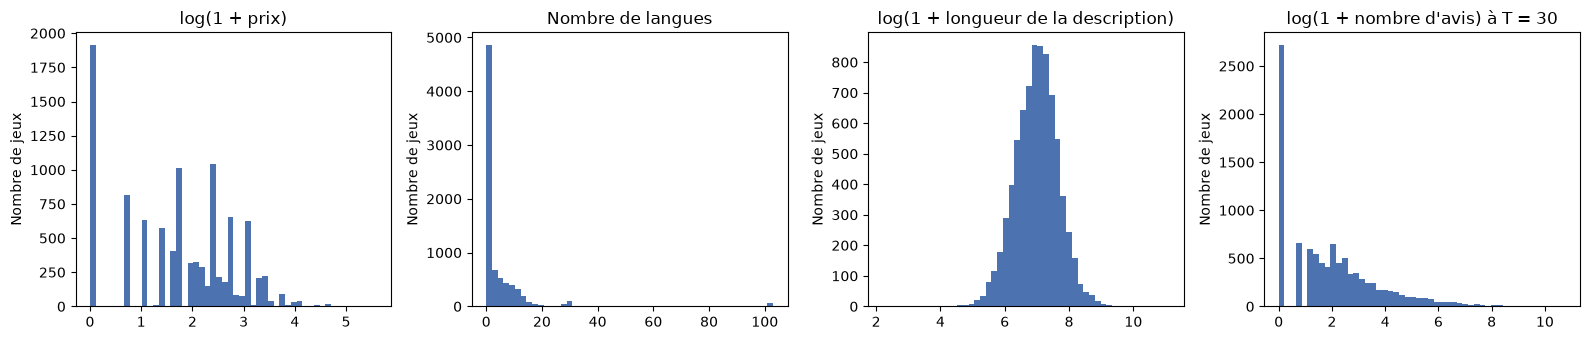

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
plots = {  # log(1 + x) pour les variables très asymétriques, sinon on ne voit qu'une barre
    "log(1 + prix)": eda["log_price"],
    "Nombre de langues": eda["n_languages"],
    "log(1 + longueur de la description)": np.log1p(eda["desc_length"]),
    "log(1 + nombre d'avis) à T = 30": np.log1p(eda["n_reviews"]),
}
for ax, (title, values) in zip(axes, plots.items()):
    ax.hist(values.dropna(), bins=50, color="#4C72B0")
    ax.set_title(title)
    ax.set_ylabel("Nombre de jeux")
plt.tight_layout()
plt.show()

**Distributions et valeurs aberrantes :**
- **Prix :** 19 % des jeux sont gratuits (la barre à 0). Les autres prix sont groupés sur des valeurs « rondes » (0,99 ; 4,99 ; 9,99 ; 19,99…), d'où les barres séparées. Le maximum est 269,99.
- **Langues :** la plupart des jeux ont 1 langue (médiane = 1). 65 jeux déclarent **103 langues**, alors que les jeux suivants en ont au plus 71 : ce sont surtout de petits jeux occasionnels (*Chocolate makes you happy 7*, *Spooky Mahjong*…) qui cochent toutes les langues proposées par Steam. Ce ne sont pas des erreurs de lecture, mais une déclaration peu fiable.
- **Description :** médiane d'environ 1 100 caractères, maximum 67 520. Sans le log, toutes les valeurs sont écrasées à gauche par ces quelques descriptions très longues.
- **Avis à T = 30 :** très asymétrique. Médiane de 5 avis, maximum de 47 984, et environ 27 % des jeux à 0.

On ne supprime aucune de ces valeurs : ce sont de vrais jeux, et les supprimer biaiserait l'échantillon. Le passage au log réduit leur poids pour les modèles linéaires, et les modèles à base d'arbres n'y sont pas sensibles. Pour le module 4 : `desc_length` et `n_reviews` gagneraient à passer au log avant la régression logistique.

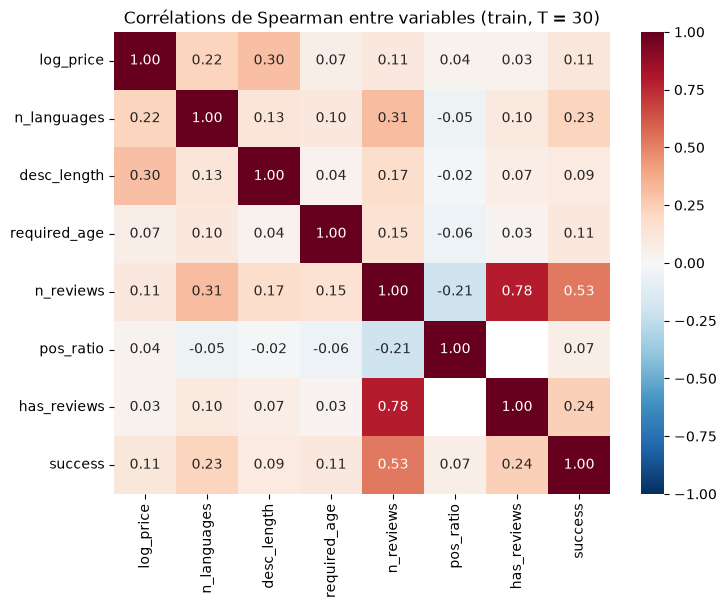

In [13]:
# Corrélation de Spearman (calculée sur les rangs) : peu sensible aux valeurs extrêmes,
# contrairement à Pearson, qui serait dominé par les quelques jeux à 40 000 avis.
# Calculée sur le train seulement.
corr = eda[eda["split"] == "train"].drop(columns=["app_id", "split"]).corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f")
plt.title("Corrélations de Spearman entre variables (train, T = 30)")
plt.show()

**Lecture :**
- **Lien avec la cible `success`** (dernière ligne) : le nombre d'avis à T = 30 est de loin le plus lié au succès (0,53). Viennent ensuite `has_reviews` (0,24) et, parmi les variables connues à la sortie, le **nombre de langues** (0,23). Le prix, l'âge requis et la longueur de la description sont faiblement liés (0,09 à 0,11). Cela explique pourquoi les modèles sont beaucoup meilleurs dès T = 7 (module 4).
- `pos_ratio` à T = 30 n'est presque pas lié au succès (0,07), alors que le succès exige ≥ 80 % d'avis positifs. C'est parce qu'il est **négativement** corrélé à `n_reviews` (−0,21) : avec 1 ou 2 avis, le ratio vaut souvent 0 ou 1 (100 %), et il se rapproche de la moyenne quand les avis s'accumulent. Un `pos_ratio` calculé sur peu d'avis est peu fiable : il doit toujours être lu avec `n_reviews`.
- Aucune paire de variables n'est presque redondante, sauf `n_reviews` et `has_reviews` (0,78), ce qui est normal : `has_reviews` vaut simplement `n_reviews > 0`.
- La case `pos_ratio` × `has_reviews` est vide : `pos_ratio` n'existe que si `has_reviews` est vrai, donc `has_reviews` est constant sur ces lignes et la corrélation ne peut pas être calculée.
- Une corrélation n'est pas une relation de cause : beaucoup de langues peut simplement signaler un éditeur plus gros.

## 5. Audit des fuites de données

Une variable est autorisée seulement si sa valeur est **connue au moment de la prédiction** (à la sortie pour T = 0, à T jours pour les signaux précoces).

| Colonne | Décision | Raison |
|---|---|---|
| `rating`, `positive_ratio`, `user_reviews` (Kozyriev) | exclue (module 1) | mesurées après la sortie, et elles définissent presque la cible |
| `price_final`, `discount` (Kozyriev), `Price` (FronkonGames) | exclue (module 1) | prix et promotion au moment de la collecte, pas au lancement |
| `steam_deck` | exclue (module 1) | compatibilité testée après la sortie de la Steam Deck (2022) |
| `Estimated owners`, `Peak CCU`, `Positive`, `Negative`, `Recommendations`, `User score`, `Metacritic score`, temps de jeu (FronkonGames) | non chargées (module 1) | mesurées après la sortie |
| `dlc_count` | **exclue** | le nombre de DLC augmente après la sortie, surtout pour les jeux qui marchent : causalité inversée |
| année de sortie | **exclue** | découpage par date : les années de validation et de test n'existent pas dans le train |
| `helpful` (avis) | **exclue** | votes cumulés jusqu'à la collecte des données, donc après T |
| `hours` (avis) | **exclue** | temps de jeu lu à la collecte : 13,6 % des avis des 30 premiers jours ont plus d'heures que le temps écoulé depuis la sortie (section 3) |
| catégories `Remote Play` (4), `Family Sharing`, `Steam Trading Cards`, accessibilité (3) | **exclues** | ajoutées après la sortie : fonctions Steam postérieures, ou cartes accordées après un seuil de ventes (section 2). Détectées grâce aux coefficients du module 4 |
| `tags` | gardée, **risque** | tags ajoutés par les joueurs, parfois après la sortie ; les jeux populaires en reçoivent plus. On garde leur présence (0/1), pas leur nombre. À tester : modèle avec et sans tags |
| autres `categories`, `price_original`, `description`, `languages`, `genres` | gardées, risque faible | valeurs lues au moment de la collecte : elles ont pu être mises à jour après la sortie, mais sans lien évident avec le succès |
| `is_recommended` (avis) | gardée, risque faible | un joueur peut modifier son avis plus tard, mais c'est rare |

## 6. Résumé : fichiers produits pour le module 4

| Fichier | Contenu | Pour quel T |
|---|---|---|
| `features_static.parquet` | `app_id` + 11 variables simples + 14 genres, 24 catégories et 167 tags en 0/1 (217 colonnes) | tous (seul fichier à T = 0) |
| `features_T7.parquet`, `features_T30.parquet`, `features_T90.parquet` | `app_id`, `n_reviews`, `pos_ratio`, `has_reviews` | à joindre à `features_static` sur `app_id` |

Le découpage vient de `target.parquet` (module 2) : les tags gardés sont choisis sur le même train que celui du modèle.

Points à retenir pour le module 4 :
- les valeurs manquantes (`pos_ratio`, colonnes FronkonGames) sont à imputer **dans le pipeline**, ajusté sur le train ;
- `desc_length` et `n_reviews` sont très asymétriques : les passer au log pour la régression logistique ;
- 9 catégories ajoutées après la sortie ont été retirées ;
- à faire plus tard (créneau 3) : sélection de variables dans le pipeline, et importance par permutation pour chaque T.